# Import libraries

In [41]:
import tensorflow as tf
import keras
from matplotlib import pyplot as plt
import numpy as np
from keras.layers import UpSampling2D,MaxPool2D,Conv2D
from keras.models import Sequential
import warnings
warnings.filterwarnings("ignore")

# load dataset

In [2]:
(x_train,_), (x_test,_)=keras.datasets.mnist.load_data(path="mnist.npz")


# Data processing

In [14]:
x_train=x_train.reshape(60000,28,28,1)
x_test=x_test.reshape(10000,28,28,1)

## normalize 

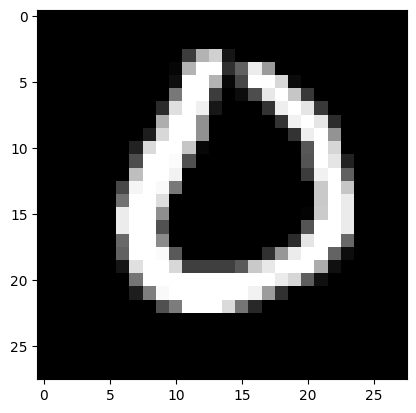

In [23]:
plt.imshow(x_train[2500],cmap='grey')

In [3]:
x_train=x_train/255.0
x_test=x_test/255.0

## Add synthetic noise

In [35]:
x_train_noise=x_train + 0.2 *np.random.normal(loc=0.10, scale=1.0, size=x_train.shape)
x_test_noise=x_test + 0.2 *np.random.normal(loc=0.0, scale=1.0, size=x_test.shape)

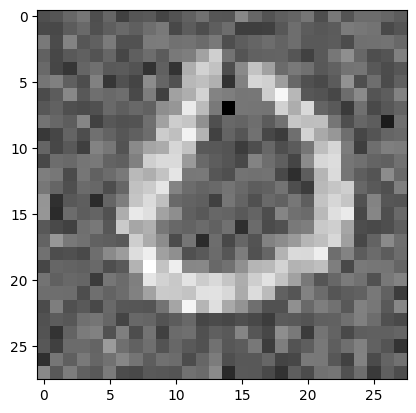

In [36]:
plt.imshow(x_train_noise[2500],cmap='grey')

## Clip values to valid image

In [37]:
x_train_clipped=np.clip(a=x_train_noise, a_min=0., a_max=1.)
x_test_clipped=np.clip(a=x_test_noise, a_min=0., a_max=1.)

# Build Encoder -decoder model

In [38]:
model=Sequential()
##encoder
model.add(Conv2D( filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',input_shape=(28,28,1)))
model.add(MaxPool2D( pool_size=(2, 2)))
model.add(Conv2D( filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',))
model.add(MaxPool2D( pool_size=(2, 2)))
##decoder
model.add(Conv2D( filters=32,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',input_shape=(28,28,1)))
model.add(UpSampling2D(size=(2, 2)))
model.add(Conv2D( filters=8,kernel_size=(3,3),strides=(1, 1),padding='same',activation='relu',))
model.add(UpSampling2D(size=(2, 2)))
model.summary()

C:\Users\sathy\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_20 (Conv2D)                   │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_10 (MaxPooling2D)      │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_21 (Conv2D)                   │ (None, 14, 14, 8)           │           2,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_11 (MaxPooling2D)      │ (None, 7, 7, 8)             │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_22 (Conv2D)                   │ (None, 7, 7, 32)            │           2,336 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_8 (UpSampling2D)       │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_23 (Conv2D)                   │ (None, 14, 14, 8)           │           2,312 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ up_sampling2d_9 (UpSampling2D)       │ (None, 28, 28, 8)           │               0 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 7,280 (28.44 KB)

 Trainable params: 7,280 (28.44 KB)

 Non-trainable params: 0 (0.00 B)

# Compile model

In [42]:
model.compile( optimizer='adam',
    loss="mean_squared_error",
    metrics=['accuracy'],)

# Train model

In [44]:
model.fit( x=x_train_clipped,
    y=x_train,
    batch_size=32,
    epochs=5,)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 28s 11ms/step - accuracy: 0.7370 - loss: 0.0340
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.7619 - loss: 0.0311
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 19s 10ms/step - accuracy: 0.7615 - loss: 0.0308
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 21s 11ms/step - accuracy: 0.7611 - loss: 0.0306
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.7611 - loss: 0.0305


# Evaluate model

In [48]:
model.evaluate(x_test_clipped,x_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.7640 - loss: 0.0307


[0.030675332993268967, 0.7639601826667786]

# Prediction model

In [49]:
y_pred=model.predict(x_test_clipped)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step


plt.imshow(x_test[5000],cmap='grey')

# Save model

In [52]:
model.save('dinoising.h5')

# Deploy the model

In [55]:
from keras.models import load_model
model=load_model('dinoising.h5')